In [ ]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [ ]:
# Find the uploaded Zomato CSV file
csv_files = [f for f in os.listdir('/content') if f.lower().endswith('.csv')]
zomato_file = next((f for f in csv_files if 'zomato' in f.lower()), None)

if zomato_file is None:
    raise FileNotFoundError("Please upload zomato.csv to Colab.")



In [ ]:
df = pd.read_csv('/content/' + zomato_file, low_memory=False)
df.columns = df.columns.str.strip()

print("Dataset:", zomato_file)
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
display(df.head())


Dataset: zomato.csv
Dataset shape: (7105, 12)

Columns:
['Unnamed: 0.1', 'Unnamed: 0', 'restaurant name', 'restaurant type', 'rate (out of 5)', 'num of ratings', 'avg cost (two people)', 'online_order', 'table booking', 'cuisines type', 'area', 'local address']


,Unnamed: 0.1,Unnamed: 0,restaurant name,restaurant type,rate (out of 5),num of ratings,avg cost (two people),online_order,table booking,cuisines type,area,local address
0,0,0,#FeelTheROLL,Quick Bites,3.4,7,200.0,No,No,Fast Food,Bellandur,Bellandur
1,1,1,#L-81 Cafe,Quick Bites,3.9,48,400.0,Yes,No,"Fast Food, Beverages","Byresandra,Tavarekere,Madiwala",HSR
2,2,2,#refuel,Cafe,3.7,37,400.0,Yes,No,"Cafe, Beverages",Bannerghatta Road,Bannerghatta Road
3,3,3,'@ Biryani Central,Casual Dining,2.7,135,550.0,Yes,No,"Biryani, Mughlai, Chinese",Marathahalli,Marathahalli
4,4,4,'@ The Bbq,Casual Dining,2.8,40,700.0,Yes,No,"BBQ, Continental, North Indian, Chinese, Bever...",Bellandur,Bellandur


In [ ]:

# Find columns regardless of spaces or underscores in their names
def find_col(*names):
    normalized = {
        c.lower().strip().replace("_", " "): c for c in df.columns
    }
    for name in names:
        key = name.lower().strip().replace("_", " ")
        if key in normalized:
            return normalized[key]
    raise KeyError(f"Could not find {names}. Available columns: {df.columns.tolist()}")

type_col = find_col("restaurant type")
rating_col = find_col("rate (out of 5)")
pop_col = find_col("num of ratings")
cost_col = find_col("avg cost (two people)")
online_col = find_col("online_order")
booking_col = find_col("table booking")

data = pd.DataFrame({
    "RestaurantType": df[type_col],
    "Rating": pd.to_numeric(df[rating_col], errors="coerce"),
    "Popularity": pd.to_numeric(df[pop_col], errors="coerce"),
    "Cost": pd.to_numeric(df[cost_col], errors="coerce"),
    "OnlineOrder": df[online_col],
    "TableBooking": df[booking_col]
})

# Handle missing numeric values
for col in ["Rating", "Popularity", "Cost"]:
    data[col] = data[col].fillna(data[col].median())

# Categorize rating
data["Rating"] = pd.cut(
    data["Rating"],
    bins=[-np.inf, 3.0, 4.0, np.inf],
    labels=["Low", "Average", "High"],
    right=False
).astype(str)

# Categorize popularity and price into three groups
data["Popularity"] = pd.qcut(
    data["Popularity"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
).astype(str)

data["Cost"] = pd.qcut(
    data["Cost"].rank(method="first"),
    q=3,
    labels=["Budget", "Moderate", "Premium"]
).astype(str)

# Clean categorical attributes and replace missing values
for col in ["RestaurantType", "OnlineOrder", "TableBooking"]:
    data[col] = data[col].replace(r"^\s*$", np.nan, regex=True)
    mode = data[col].mode()
    fill_value = mode.iloc[0] if not mode.empty else "Unknown"
    data[col] = data[col].fillna(fill_value).astype(str).str.strip()

data["OnlineOrder"] = data["OnlineOrder"].str.title()
data["TableBooking"] = data["TableBooking"].str.title()

print("Prepared dataset shape:", data.shape)
print("\nSample prepared records:")
display(data.head())


Prepared dataset shape: (7105, 6)

Sample prepared records:


,RestaurantType,Rating,Popularity,Cost,OnlineOrder,TableBooking
0,Quick Bites,Average,Low,Budget,No,No
1,Quick Bites,Average,Medium,Moderate,Yes,No
2,Cafe,Average,Medium,Moderate,Yes,No
3,Casual Dining,Low,High,Premium,Yes,No
4,Casual Dining,Low,Medium,Premium,Yes,No


In [ ]:

# Convert each attribute value into an item
items = pd.DataFrame({
    col: col + "=" + data[col].astype(str)
    for col in data.columns
})

# One-hot encode items into a True/False transaction matrix
transaction_matrix = pd.get_dummies(items, dtype=bool)

print("Number of transactions:", len(transaction_matrix))
print("Number of unique items:", transaction_matrix.shape[1])
display(transaction_matrix.head())


Number of transactions: 7105
Number of unique items: 94


,RestaurantType_RestaurantType=Bakery,"RestaurantType_RestaurantType=Bakery, Beverage Shop","RestaurantType_RestaurantType=Bakery, Cafe","RestaurantType_RestaurantType=Bakery, Dessert Parlor","RestaurantType_RestaurantType=Bakery, Quick Bites",RestaurantType_RestaurantType=Bar,"RestaurantType_RestaurantType=Bar, Casual Dining","RestaurantType_RestaurantType=Bar, Lounge","RestaurantType_RestaurantType=Bar, Pub",RestaurantType_RestaurantType=Beverage Shop,...,Popularity_Popularity=High,Popularity_Popularity=Low,Popularity_Popularity=Medium,Cost_Cost=Budget,Cost_Cost=Moderate,Cost_Cost=Premium,OnlineOrder_OnlineOrder=No,OnlineOrder_OnlineOrder=Yes,TableBooking_TableBooking=No,TableBooking_TableBooking=Yes
0,False,False,False,False,False,False,False,False,False,False,...,False,True,False,True,False,False,True,False,True,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,True,False,False,True,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,True,False,False,True,True,False
3,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,True,False,True,True,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,True,False,True,True,False


In [ ]:

!pip -q install mlxtend

from mlxtend.frequent_patterns import apriori, association_rules

support_used = 0.05
frequent_itemsets = apriori(
    transaction_matrix,
    min_support=support_used,
    use_colnames=True,
    max_len=3
)

# Lower support only if no frequent pairs are found
while (
    not frequent_itemsets.empty
    and not frequent_itemsets["itemsets"].map(len).ge(2).any()
    and support_used > 0.01
):
    support_used = round(support_used - 0.01, 2)
    frequent_itemsets = apriori(
        transaction_matrix,
        min_support=support_used,
        use_colnames=True,
        max_len=3
    )

print("Minimum support used:", support_used)
print("Frequent itemsets found:", len(frequent_itemsets))

if not frequent_itemsets.empty:
    display(
        frequent_itemsets.sort_values(
            "support", ascending=False
        ).head(15)
    )
else:
    print("No frequent itemsets found. Check the prepared data.")


Minimum support used: 0.05
Frequent itemsets found: 212


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
15,0.895285,(TableBooking_TableBooking=No)
4,0.672625,(Rating_Rating=Average)
45,0.643772,"(TableBooking_TableBooking=No, Rating_Rating=A..."
14,0.524560,(OnlineOrder_OnlineOrder=Yes)
13,0.475440,(OnlineOrder_OnlineOrder=No)
88,0.473610,"(TableBooking_TableBooking=No, OnlineOrder_Onl..."
86,0.421675,"(TableBooking_TableBooking=No, OnlineOrder_Onl..."
3,0.399719,(RestaurantType_RestaurantType=Quick Bites)
36,0.398170,"(TableBooking_TableBooking=No, RestaurantType_..."
44,0.355102,"(OnlineOrder_OnlineOrder=Yes, Rating_Rating=Av..."


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:

if frequent_itemsets.empty or not frequent_itemsets["itemsets"].map(len).ge(2).any():
    raise ValueError("No frequent pairs found. Lower the support threshold and rerun Step 4.")

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.30
)

# Keep rules with lift >= 1
rules = rules[rules["lift"] >= 1].copy()

# Make the itemsets readable
rules["antecedents"] = rules["antecedents"].apply(
    lambda x: ", ".join(sorted(x))
)
rules["consequents"] = rules["consequents"].apply(
    lambda x: ", ".join(sorted(x))
)

rules = rules.sort_values(
    ["confidence", "lift"],
    ascending=False
).reset_index(drop=True)

display(
    rules[["antecedents", "consequents", "support",
           "confidence", "lift"]].head(15)
)

print("Association rules found:", len(rules))


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedents,consequents,support,confidence,lift
0,RestaurantType_RestaurantType=Delivery,TableBooking_TableBooking=No,0.050387,1.000000,1.116963
1,"Rating_Rating=Low, RestaurantType_RestaurantTy...",TableBooking_TableBooking=No,0.069247,1.000000,1.116963
2,"Cost_Cost=Budget, Rating_Rating=Low",TableBooking_TableBooking=No,0.061647,1.000000,1.116963
3,"Cost_Cost=Budget, Popularity_Popularity=Low",TableBooking_TableBooking=No,0.160732,1.000000,1.116963
4,"Cost_Cost=Budget, OnlineOrder_OnlineOrder=No",TableBooking_TableBooking=No,0.171569,1.000000,1.116963
5,"Cost_Cost=Budget, RestaurantType_RestaurantTyp...",TableBooking_TableBooking=No,0.221393,0.999365,1.116253
6,Cost_Cost=Budget,TableBooking_TableBooking=No,0.333005,0.999155,1.116019
7,"Popularity_Popularity=Low, RestaurantType_Rest...",TableBooking_TableBooking=No,0.166502,0.999155,1.116019
8,"Cost_Cost=Budget, Rating_Rating=Average",TableBooking_TableBooking=No,0.246587,0.998860,1.115689
9,"Cost_Cost=Moderate, Popularity_Popularity=Low",TableBooking_TableBooking=No,0.116256,0.998791,1.115612


Association rules found: 441


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

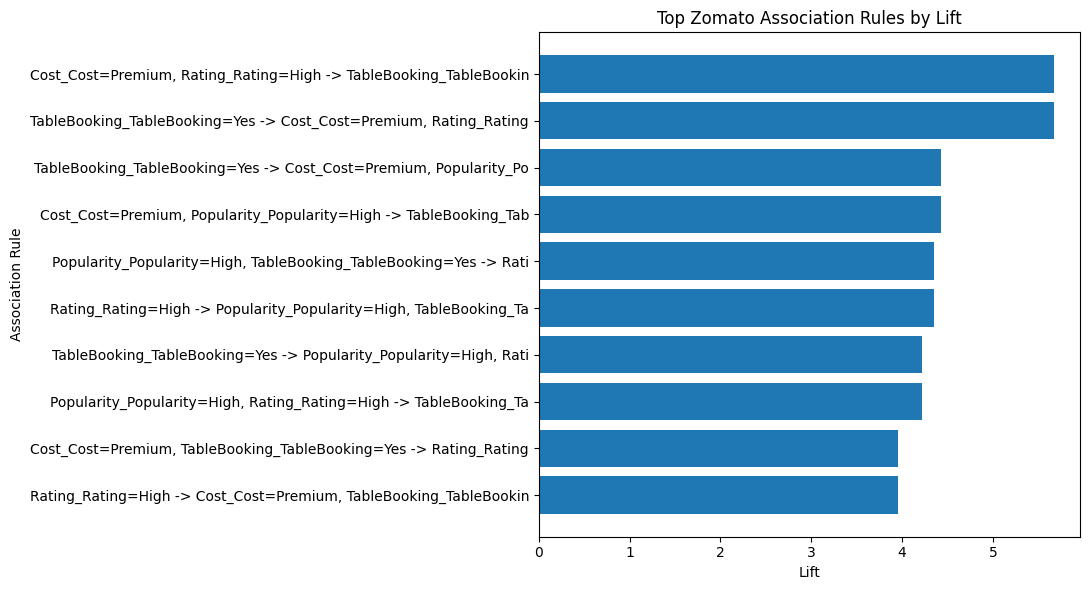

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:

if rules.empty:
    print("No rules met the chosen confidence and lift thresholds.")
else:
    top_rules = rules.sort_values(
        ["lift", "confidence"],
        ascending=False
    ).head(10).copy()

    top_rules["Rule"] = top_rules.apply(
        lambda r: f"{r['antecedents']} -> {r['consequents']}",
        axis=1
    )
    top_rules["Rule"] = top_rules["Rule"].str.slice(0, 65)

    plt.figure(figsize=(11, 6))
    plt.barh(top_rules["Rule"][::-1], top_rules["lift"][::-1])
    plt.xlabel("Lift")
    plt.ylabel("Association Rule")
    plt.title("Top Zomato Association Rules by Lift")
    plt.tight_layout()
    plt.show()


In [ ]:

data.to_csv("zomato_apriori_prepared.csv", index=False)
transaction_matrix.to_csv("zomato_apriori_transactions.csv", index=False)

if not rules.empty:
    rules[["antecedents", "consequents", "support",
           "confidence", "lift"]].to_csv(
        "zomato_apriori_rules.csv", index=False
    )

from google.colab import files
files.download("zomato_apriori_prepared.csv")


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

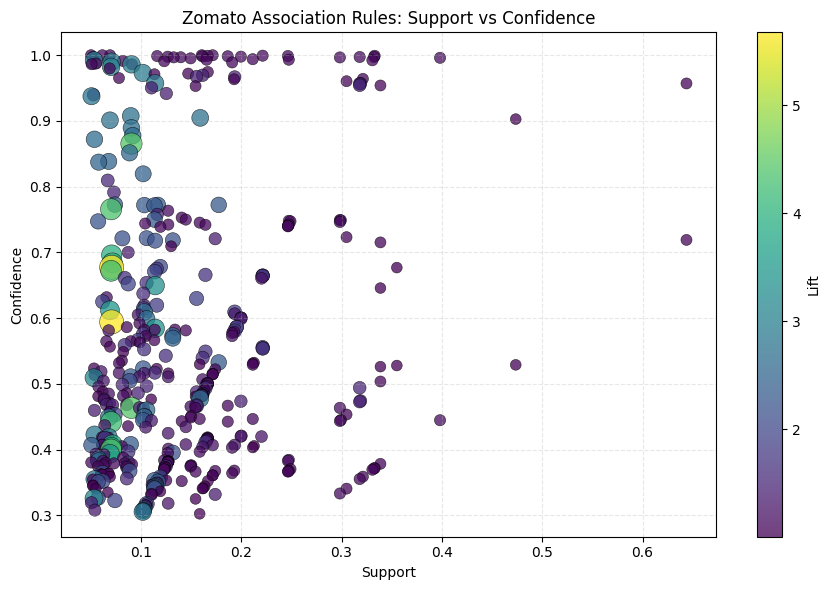

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if rules.empty:
    print("No association rules available to visualize.")
else:
    plot_rules = rules.dropna(
        subset=["support", "confidence", "lift"]
    ).copy()

    # Scale marker sizes according to lift
    lift_min = plot_rules["lift"].min()
    lift_max = plot_rules["lift"].max()

    if lift_max == lift_min:
        sizes = np.full(len(plot_rules), 100)
    else:
        sizes = 60 + 240 * (
            (plot_rules["lift"] - lift_min) /
            (lift_max - lift_min)
        )

    plt.figure(figsize=(9, 6))

    scatter = plt.scatter(
        plot_rules["support"],
        plot_rules["confidence"],
        c=plot_rules["lift"],
        s=sizes,
        cmap="viridis",
        alpha=0.75,
        edgecolors="black",
        linewidths=0.4
    )

    plt.colorbar(scatter, label="Lift")
    plt.title("Zomato Association Rules: Support vs Confidence")
    plt.xlabel("Support")
    plt.ylabel("Confidence")
    plt.grid(True, linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

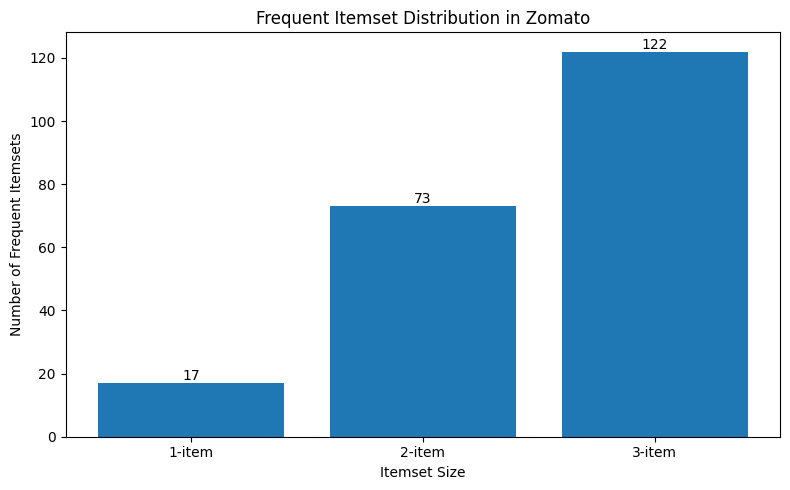

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Frequent itemset counts:
Itemset Size
1     17
2     73
3    122
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

if frequent_itemsets.empty:
    print("No frequent itemsets available to visualize.")
else:
    # Count the number of items in each frequent itemset
    frequent_itemsets["Itemset Size"] = frequent_itemsets["itemsets"].apply(len)

    size_counts = (
        frequent_itemsets["Itemset Size"]
        .value_counts()
        .sort_index()
        .reindex([1, 2, 3], fill_value=0)
    )

    plt.figure(figsize=(8, 5))
    bars = plt.bar(
        ["1-item", "2-item", "3-item"],
        size_counts.values
    )

    plt.title("Frequent Itemset Distribution in Zomato")
    plt.xlabel("Itemset Size")
    plt.ylabel("Number of Frequent Itemsets")

    for bar, count in zip(bars, size_counts.values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            str(count),
            ha="center",
            va="bottom"
        )

    plt.tight_layout()
    plt.show()

    print("Frequent itemset counts:")
    print(size_counts)


In [ ]:
from google.colab import files

if not rules.empty:
    rules[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].to_csv("zomato_apriori_rules.csv", index=False)

    files.download("zomato_apriori_rules.csv")
    print("Association rules saved successfully.")
else:
    print("No rules available to download.")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

Association rules saved successfully.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag